# 99. Evaluación final en test (una sola vez)

**Qué hace.** Evalúa el pipeline congelado sobre los 20 registros de test (10 sujetos), siguiendo `docs/plan_test.md` sin cambios: minutos evaluados (§4), H2 con M1 y M2 (§5), resultados secundarios (§6) y los desvíos 9.2 (acierto contra el AHI) y 9.3 (A contra el resto). Todo lo que se calcula acá estaba fijado antes de abrir test.

**Reglas.**
1. Se corre **una sola vez**, sobre el commit con la etiqueta `congelado-test`. La primera celda de código lo verifica y se detiene si no es así.
2. No se cambia nada del pipeline, de los umbrales ni de las medidas después de ver un resultado (§7). Si aparece un error de código, se corrige, se declara en `plan_test.md` §9 y se reportan **las dos** corridas.
3. Los umbrales se leen de `docs/umbrales_desarrollo.json` (notebook 11), y se verifica que coincidan con `plan_test.md` §3.
4. Se reportan **todos** los resultados, sean favorables o no. Las conclusiones de H2 se dan por medida, sin combinarlas.
5. Se commitea con sus salidas tal como quedan.

**Modo ensayo.** Con `MODO_ENSAYO = True` el notebook corre igual, pero sobre unos registros de **desarrollo**, sin exigir la etiqueta y guardando en otra carpeta. Sirve para comprobar que todo funciona antes de congelar, sin tocar test. **Para la corrida real tiene que estar en `False`.**

In [1]:
MODO_ENSAYO = False          # True: prueba con registros de desarrollo, sin tocar test

import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import RESULTS_DIR, SEED, SPLIT_CSV
from src.data import load_apnea_labels, load_record_info
from src.evaluation.final import fill_from_nearest, h1_subject_deltas, h2_bootstrap
from src.evaluation.metrics import category_from_minutes, minute_metrics, night_minutes, record_metrics
from src.features.build import record_hrv_table, record_minute_table, record_series
from src.stats.nested import record_agreement_boot
from src.stats.tests import holm, paired_subject_test

N_BOOT = 10_000
split = pd.read_csv(SPLIT_CSV).set_index("record")

def git(*args):
    return subprocess.run(["git", *args], cwd=ROOT, capture_output=True, text=True).stdout.strip()

if MODO_ENSAYO:
    # Primer registro de cada uno de los primeros 6 sujetos de desarrollo.
    dev = split[split.set == "dev"]
    REGISTROS = list(dev.groupby("subject", sort=True).head(1).index[:6])
    SALIDA = RESULTS_DIR / "ensayo_99"
    print("*** MODO ENSAYO: registros de DESARROLLO, no es la evaluación de test ***")
else:
    etiqueta = git("describe", "--exact-match", "--tags", "HEAD")
    assert etiqueta == "congelado-test", f"HEAD no tiene la etiqueta congelado-test (tiene: {etiqueta or 'ninguna'})"
    assert git("status", "--porcelain", "--", "src", "docs", "data/split.csv") == "", \
        "Hay cambios sin commitear en src/, docs/ o data/split.csv"
    REGISTROS = list(split.index[split.set == "test"])
    SALIDA = RESULTS_DIR / "test"
    assert len(REGISTROS) == 20 and split.loc[REGISTROS, "subject"].nunique() == 10

SALIDA.mkdir(parents=True, exist_ok=True)
FIG = SALIDA / "figuras"; FIG.mkdir(exist_ok=True)
subject_of = split.loc[REGISTROS, "subject"]
print(f"commit {git('rev-parse', '--short', 'HEAD')} | {len(REGISTROS)} registros de {subject_of.nunique()} sujetos")
print("categorías (regla de la base):", split.loc[REGISTROS, "category"].value_counts().reindex(list("ABC"), fill_value=0).to_dict())

commit 1af5d39 | 20 registros de 10 sujetos
categorías (regla de la base): {'A': 12, 'B': 3, 'C': 5}


In [2]:
umb = json.loads((ROOT / "docs" / "umbrales_desarrollo.json").read_text(encoding="utf-8"))
THR = {"F": float(umb["umbrales"]["F"]), "HRV": float(umb["umbrales"]["VLF"])}
assert umb["regla"] == "score >= umbral"
# Los mismos valores que plan_test.md §3.
assert abs(THR["F"] - (-6.948641462292339)) < 1e-12 and abs(THR["HRV"] - 0.001258477270410224) < 1e-15
print("umbrales congelados:", THR)

umbrales congelados: {'F': -6.948641462292339, 'HRV': 0.001258477270410224}


## Features de cada registro

Con el pipeline congelado (`plan_test.md` §3): marcas `.qrs` con parábola, filtro 0,5–45 Hz orden 3, EDR por área, sin Wiener.
- **F:** log de la potencia cruzada RR–EDR en 0,01–0,05 Hz, ventana de 240 s, Welch de 3 segmentos.
- **Referencia:** potencia VLF (0,01–0,04 Hz) del RR con Lomb, ventana de 180 s.
- **Para la réplica de H1 (§6.3):** coherencias en las bandas del CPC publicado y del esquema v2, ventana de 512 s.

In [3]:
BANDA_F = {"ap_l": (0.01, 0.05)}
BANDAS_H1 = {"cpc_lenta": (0.01, 0.1), "cpc_resp": (0.1, 0.4),
             "v2_lenta": (0.01, 0.15), "v2_resp": (0.15, 0.4)}
CACHE = SALIDA / "features"; CACHE.mkdir(exist_ok=True)

tablas, tablas_h1 = [], []
for i, rec in enumerate(REGISTROS, 1):
    f_min, f_h1 = CACHE / f"{rec}_minutos.parquet", CACHE / f"{rec}_h1.parquet"
    if not (f_min.exists() and f_h1.exists()):
        s = record_series(rec)
        f = record_minute_table(rec, 240, BANDA_F, series=s)
        h = record_hrv_table(rec, 180, series=s)
        t = f[["record", "minute", "label", "corrected"]].assign(F=np.log(np.maximum(f["xp_ap_l"], 1e-12)))
        t = t.merge(h[["minute", "vlf"]].rename(columns={"vlf": "HRV"}), on="minute", how="outer")
        lab = load_apnea_labels(rec)
        t["record"], t["label"] = rec, lab[t["minute"].to_numpy()]
        t.to_parquet(f_min)
        record_minute_table(rec, 512, BANDAS_H1, series=s).to_parquet(f_h1)
    tablas.append(pd.read_parquet(f_min)); tablas_h1.append(pd.read_parquet(f_h1))
    print(f"[{i}/{len(REGISTROS)}] {rec}", flush=True)

feat = pd.concat(tablas, ignore_index=True)
feat["subject"] = feat.record.map(subject_of)
tab_h1 = pd.concat(tablas_h1, ignore_index=True)
tab_h1["subject"] = tab_h1.record.map(subject_of)

[1/20] a06
[2/20] a07
[3/20] a11
[4/20] a16
[5/20] b04
[6/20] b05
[7/20] c04
[8/20] c08
[9/20] x01
[10/20] x02
[11/20] x06
[12/20] x11
[13/20] x13
[14/20] x15
[15/20] x24
[16/20] x26
[17/20] x29
[18/20] x30
[19/20] x31
[20/20] x32


## §4. Minutos que se evalúan

- **Análisis principal:** minutos con etiqueta, con 20 % o menos de RR corregidos, y con F y referencia calculables. Las dos features se evalúan sobre los mismos minutos.
- **Sensibilidad:** todos los minutos con etiqueta. Un minuto sin feature válida toma los valores del minuto válido más cercano del mismo registro.

In [4]:
# Todos los minutos con etiqueta de cada registro, tengan o no features.
filas = []
for rec in REGISTROS:
    lab = load_apnea_labels(rec)
    m = np.flatnonzero(lab >= 0)
    filas.append(pd.DataFrame({"record": rec, "minute": m, "label": lab[m]}))
todos = pd.concat(filas, ignore_index=True).merge(
    feat[["record", "minute", "corrected", "F", "HRV"]], on=["record", "minute"], how="left")
todos["subject"] = todos.record.map(subject_of)
todos["valido"] = (todos.corrected <= 0.2) & np.isfinite(todos.F) & np.isfinite(todos.HRV)

principal = todos[todos.valido].reset_index(drop=True)

completos = []
for rec, g in todos.groupby("record", sort=False):
    v = fill_from_nearest(g.minute.to_numpy(), {"F": g.F.to_numpy(), "HRV": g.HRV.to_numpy()}, g.valido.to_numpy())
    completos.append(g.assign(F=v["F"], HRV=v["HRV"]))
completos = pd.concat(completos, ignore_index=True)
completos = completos[np.isfinite(completos.F) & np.isfinite(completos.HRV)].reset_index(drop=True)

fuera = 1 - todos.valido.mean()
print(f"minutos con etiqueta: {len(todos):,} | evaluados: {len(principal):,} | afuera: {fuera:.1%}")
print(f"  sin F o referencia calculable: {(~(np.isfinite(todos.F) & np.isfinite(todos.HRV))).sum():,} | "
      f"con más de 20 % de RR corregidos: {(todos.corrected > 0.2).sum():,}")
print(f"apnea en los minutos evaluados: {principal.label.mean():.1%} | sensibilidad (todos los minutos): {len(completos):,}")
display(todos.groupby("record").valido.agg(evaluados="sum", total="size")
        .assign(fraccion_afuera=lambda d: 1 - d.evaluados / d.total).round(3).T)

minutos con etiqueta: 9,754 | evaluados: 8,556 | afuera: 12.3%
  sin F o referencia calculable: 112 | con más de 20 % de RR corregidos: 1,089
apnea en los minutos evaluados: 43.4% | sensibilidad (todos los minutos): 9,754


record,a06,a07,a11,a16,b04,b05,c04,c08,x01,x02,x06,x11,x13,x15,x24,x26,x29,x30,x31,x32
evaluados,369.000,506.00,463.000,477.00,398.000,353.000,126.000,491.000,508.000,467.000,440.000,450.000,472.000,448.0,412.00,516.000,65.000,509.000,553.000,533.000
total,510.000,511.00,466.000,482.00,429.000,433.000,482.000,513.000,523.000,469.000,450.000,457.000,506.000,498.0,429.00,520.000,470.000,511.000,557.000,538.000
fraccion_afuera,0.276,0.01,0.006,0.01,0.072,0.185,0.739,0.043,0.029,0.004,0.022,0.015,0.067,0.1,0.04,0.008,0.862,0.004,0.007,0.009


## §5. Hipótesis principal: H2

F contra la referencia, sobre los mismos minutos y registros. Diferencia = F − referencia; bootstrap de los 10 sujetos con 10.000 remuestreos (semilla 2026); IC 95 % por percentiles; p bilateral = 2 × min(fracción de diferencias ≤ 0, fracción ≥ 0). Los dos p se corrigen por Holm.

**Regla de decisión, por medida:** se confirma si el p de Holm es < 0,05 y la diferencia favorece a F; se rechaza si es < 0,05 y favorece a la referencia; si no, **no muestra diferencia** con estos datos (que no quiere decir que sean iguales).

In [5]:
def evaluar_h2(d):
    r = h2_bootstrap(d.F, d.HRV, d.label, d.record, d.subject, THR["F"], THR["HRV"], n_boot=N_BOOT, seed=SEED)
    r["p (Holm)"] = holm(r.p.to_numpy())
    r["resultado"] = np.where(r["p (Holm)"] >= 0.05, "no muestra diferencia",
                              np.where(r.diferencia > 0, "se confirma H2", "se rechaza H2"))
    return r

h2 = evaluar_h2(principal)
h2.to_csv(SALIDA / "h2.csv")
display(h2.round(4))

,F,referencia,diferencia,ic_lo,ic_hi,p,remuestreos_validos,p (Holm),resultado
medida,,,,,,,,,
M1: AUC por minuto,0.7852,0.7925,-0.0073,-0.1624,0.1121,0.8974,10000,1.0,no muestra diferencia
M2: acierto por registro,0.6340,0.6128,0.0211,-0.5432,0.5142,0.8410,10000,1.0,no muestra diferencia


## §6.1. Por minuto

Sensibilidad, especificidad, exactitud y matriz de confusión con los umbrales de desarrollo. Como referencia (no como meta): los mejores métodos del Challenge 2000, con aprendizaje automático, llegaron a ~90 % de exactitud por minuto.

In [6]:
def por_minuto(d):
    out, matrices = {}, {}
    for fam in ("F", "HRV"):
        m = minute_metrics(d.label.to_numpy(), (d[fam] >= THR[fam]).to_numpy())
        matrices[fam] = m.pop("matriz")
        out[fam] = m
    return pd.DataFrame(out).T, matrices

minuto, matrices = por_minuto(principal)
minuto.to_csv(SALIDA / "por_minuto.csv")
display(minuto.astype(float).round(4))
for fam, mat in matrices.items():
    print(f"matriz de confusión, {fam} (filas: real; columnas: estimado)"); display(mat)

,TP,FP,TN,FN,Se,Esp,exactitud,exactitud_balanceada
F,2934.0,1735.0,3108.0,779.0,0.7902,0.6418,0.7062,0.7160
HRV,2728.0,1520.0,3323.0,985.0,0.7347,0.6861,0.7072,0.7104


matriz de confusión, F (filas: real; columnas: estimado)


estimado,normal,apnea
real,,
normal,3108,1735
apnea,779,2934


matriz de confusión, HRV (filas: real; columnas: estimado)


estimado,normal,apnea
real,,
normal,3323,1520
apnea,985,2728


## §6.2. Por registro

- Minutos de apnea por hora, estimados contra anotados, con Bland–Altman.
- Categoría A/B/C estimada contra la real, con la regla de la base (A ≥ 100 minutos de apnea; B de 5 a 99; C < 5), contadas sobre los minutos evaluados, como en los notebooks 12 y 13. Con 3 registros B en test, esa clase pesa poco.
- **Desvío 9.3:** A contra el resto, con la misma regla.
- **Desvío 9.2:** Spearman entre la fracción de minutos estimada como apnea y el AHI de la base, con IC por bootstrap de sujetos. Descriptivo.

,Spearman min/h,sesgo min/h,lím. inf.,lím. sup.,A/B/C correcta,A contra el resto correcta
F,0.634,7.269,-27.943,42.482,0.45,0.7
HRV,0.613,5.104,-25.426,35.634,0.60,0.7



F: categoría A/B/C (filas: real; columnas: estimada)


estimada,A,B,C
real,,,
A,9,3,0
B,3,0,0
C,0,5,0


F: A contra el resto (9.3)


estimada,A,resto
real,,
A,9,3
B,3,0
C,0,5



HRV: categoría A/B/C (filas: real; columnas: estimada)


estimada,A,B,C
real,,,
A,11,1,0
B,2,1,0
C,3,2,0


HRV: A contra el resto (9.3)


estimada,A,resto
real,,
A,11,1
B,2,1
C,3,2



Spearman contra el AHI (9.2):


,spearman,ic_lo,ic_hi
est_F,0.701,0.145,0.909
est_HRV,0.675,-0.044,0.914
est_F - est_HRV,0.026,-0.474,0.503


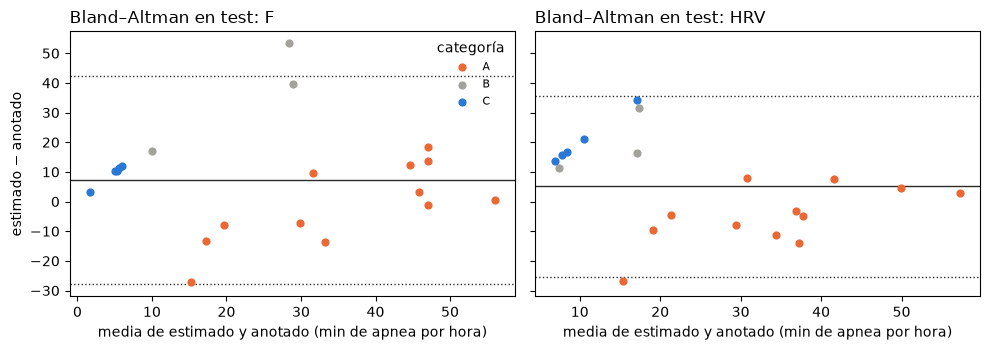

In [7]:
def por_registro(d):
    res = {}
    for fam in ("F", "HRV"):
        nm = night_minutes(d.record, d.label, (d[fam] >= THR[fam]).to_numpy())
        res[fam] = (nm, record_metrics(nm.min_estimados, nm.min_anotados, nm.horas, records=nm.index))
    return res

def resumen_registro(res):
    filas = {}
    for fam, (nm, r) in res.items():
        t = r["tabla"]
        a_est, a_real = t.categoria_estimada == "A", t.categoria_real == "A"
        filas[fam] = {"Spearman min/h": r["spearman"], "sesgo min/h": r["sesgo"],
                      "lím. inf.": r["lim_inf"], "lím. sup.": r["lim_sup"],
                      "A/B/C correcta": r["acierto_categoria"],
                      "A contra el resto correcta": float((a_est == a_real).mean())}
    return pd.DataFrame(filas).T

noches = por_registro(principal)
resumen = resumen_registro(noches)
resumen.to_csv(SALIDA / "por_registro.csv")
display(resumen.round(3))

for fam in ("F", "HRV"):
    t = noches[fam][1]["tabla"]
    print(f"\n{fam}: categoría A/B/C (filas: real; columnas: estimada)"); display(noches[fam][1]["matriz_categorias"])
    print(f"{fam}: A contra el resto (9.3)")
    display(pd.crosstab(t.categoria_real, np.where(t.categoria_estimada == "A", "A", "resto"),
                        rownames=["real"], colnames=["estimada"]))

# Desvío 9.2: contra el AHI de la base
info = load_record_info().set_index("record")
nm_f = noches["F"][0]
t_ahi = pd.DataFrame({"subject": subject_of.loc[nm_f.index].to_numpy(),
                      "real": info.loc[nm_f.index, "AHI"].to_numpy(float),
                      "est_F": nm_f.min_estimados / nm_f.minutos_evaluados,
                      "est_HRV": noches["HRV"][0].loc[nm_f.index, "min_estimados"] / nm_f.minutos_evaluados},
                     index=nm_f.index)
ahi = record_agreement_boot(t_ahi, cols=("est_F", "est_HRV"), n_boot=N_BOOT, seed=SEED)
ahi.to_csv(SALIDA / "ahi.csv")
print("\nSpearman contra el AHI (9.2):"); display(ahi.astype(float).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
COLOR = {"A": "#eb6834", "B": "#a3a29c", "C": "#2a78d6"}
for ax, fam in zip(axes, ("F", "HRV")):
    r = noches[fam][1]; t = r["tabla"]
    for c in "ABC":
        s = t.categoria_real == c
        ax.scatter(t.media[s], t.diferencia[s], s=24, color=COLOR[c], label=c, zorder=3)
    for v, ls in ((r["sesgo"], "-"), (r["lim_inf"], ":"), (r["lim_sup"], ":")):
        ax.axhline(v, color="#2b2b2b", lw=1, ls=ls)
    ax.set_xlabel("media de estimado y anotado (min de apnea por hora)")
    ax.set_title(f"Bland–Altman en test: {fam}", loc="left")
axes[0].set_ylabel("estimado − anotado"); axes[0].legend(frameon=False, fontsize=8, title="categoría")
fig.tight_layout(); fig.savefig(FIG / "99_bland_altman.png")

## §6.3. Réplica de H1

En los registros A/B de test se repite la prueba principal de E2 con su misma configuración: CR = coherencia lenta / coherencia respiratoria, ventana de 512 s, bandas del CPC publicado (0,01–0,1 / 0,1–0,4 Hz) y del esquema v2 (0,01–0,15 / 0,15–0,4 Hz); por registro, mediana con apnea − mediana sin apnea (minutos con 20 % o menos de RR corregidos, al menos 5 de cada clase); por sujeto, el promedio; Wilcoxon de dos colas; Holm sobre las dos configuraciones. Es una réplica con poca potencia y se reporta como tal.

In [8]:
CONFIGS_H1 = {"CPC publicado": ("cpc_lenta", "cpc_resp"), "esquema v2": ("v2_lenta", "v2_resp")}
AB = [r for r in REGISTROS if split.loc[r, "category"] in ("A", "B")]

def replica_h1(max_corr):
    t = tab_h1[tab_h1.record.isin(AB)]
    filas = []
    for nombre, (lo, hi) in CONFIGS_H1.items():
        dif, _ = h1_subject_deltas(t, t[f"coh_{lo}"] / t[f"coh_{hi}"], max_corrected=max_corr)
        r = paired_subject_test(dif.to_numpy(), seed=SEED)
        filas.append({"configuración": nombre, "sujetos": r["n"], "positivos": r["positivos"],
                      "mediana Δ CR": r["mediana"], "IC mediana": "{:.3f} a {:.3f}".format(*r["ic_mediana"]),
                      "r rango-biserial": r["r_rb"], "p": r["p"]})
    out = pd.DataFrame(filas).set_index("configuración")
    out["p (Holm)"] = holm(out.p.to_numpy())
    return out

print(f"{len(AB)} registros A/B de {subject_of.loc[AB].nunique()} sujetos")
h1 = replica_h1(0.2)
h1.to_csv(SALIDA / "h1_replica.csv")
display(h1.round(4))

15 registros A/B de 8 sujetos


,sujetos,positivos,mediana Δ CR,IC mediana,r rango-biserial,p,p (Holm)
configuración,,,,,,,
CPC publicado,8,4,-0.0131,-0.112 a 0.090,-0.1111,0.8438,1.0
esquema v2,8,3,-0.0216,-0.062 a 0.122,0.0556,0.9453,1.0


## §6.4. Sensibilidad: todos los minutos con etiqueta

Lo mismo que arriba, con todos los minutos con etiqueta (§4) y, para H1, sin la exclusión por RR corregidos.

In [9]:
print(f"minutos: {len(completos):,}")
h2_todos = evaluar_h2(completos); h2_todos.to_csv(SALIDA / "h2_todos.csv")
print("H2:"); display(h2_todos.round(4))
minuto_todos, _ = por_minuto(completos); minuto_todos.to_csv(SALIDA / "por_minuto_todos.csv")
print("Por minuto:"); display(minuto_todos.astype(float).round(4))
resumen_todos = resumen_registro(por_registro(completos)); resumen_todos.to_csv(SALIDA / "por_registro_todos.csv")
print("Por registro:"); display(resumen_todos.round(3))
h1_todos = replica_h1(None); h1_todos.to_csv(SALIDA / "h1_replica_todos.csv")
print("Réplica de H1 sin exclusión por calidad:"); display(h1_todos.round(4))

minutos: 9,754
H2:


,F,referencia,diferencia,ic_lo,ic_hi,p,remuestreos_validos,p (Holm),resultado
medida,,,,,,,,,
M1: AUC por minuto,0.7724,0.7655,0.0069,-0.1555,0.1313,0.9416,10000,1.0,no muestra diferencia
M2: acierto por registro,0.6098,0.4634,0.1464,-0.5001,0.6175,0.5780,10000,1.0,no muestra diferencia


Por minuto:


,TP,FP,TN,FN,Se,Esp,exactitud,exactitud_balanceada
F,3047.0,2153.0,3763.0,791.0,0.7939,0.6361,0.6982,0.715
HRV,2830.0,2161.0,3755.0,1008.0,0.7374,0.6347,0.6751,0.686


Por registro:


,Spearman min/h,sesgo min/h,lím. inf.,lím. sup.,A/B/C correcta,A contra el resto correcta
F,0.610,8.988,-26.864,44.839,0.55,0.70
HRV,0.463,7.615,-27.799,43.030,0.55,0.55


Réplica de H1 sin exclusión por calidad:


,sujetos,positivos,mediana Δ CR,IC mediana,r rango-biserial,p,p (Holm)
configuración,,,,,,,
CPC publicado,8,3,-0.0225,-0.114 a 0.093,-0.2222,0.6406,1.0
esquema v2,8,3,-0.0245,-0.062 a 0.122,0.0556,0.9453,1.0


In [10]:
if MODO_ENSAYO:
    print("*** ENSAYO TERMINADO. Antes de la corrida real: MODO_ENSAYO = False, congelar y etiquetar. ***")
else:
    print(f"Evaluación de test terminada sobre {git('rev-parse', '--short', 'HEAD')} (congelado-test). "
          f"Resultados en {SALIDA.relative_to(ROOT)}. Commitear el notebook con sus salidas, sin cambios.")

Evaluación de test terminada sobre 1af5d39 (congelado-test). Resultados en results\test. Commitear el notebook con sus salidas, sin cambios.


## Resultados

- **H2, M1 (AUC por minuto):** F 0,785 contra 0,793 de la referencia; diferencia −0,007 (IC 95 % −0,162 a +0,112; p de Holm 1). **No muestra diferencia.**
- **H2, M2 (acierto por registro):** F 0,634 contra 0,613; diferencia +0,021 (IC −0,543 a +0,514; p de Holm 1). **No muestra diferencia.** Con 10 sujetos los intervalos son muy anchos: los datos son compatibles tanto con una ventaja clara de F como con una de la referencia.
- **Secundarios.** Por minuto, F: sensibilidad 0,790, especificidad 0,642, exactitud 0,706; referencia: 0,735, 0,686 y 0,707. Por noche, F sobreestima la apnea (+7,3 minutos por hora; límites de −27,9 a +42,5) y las 5 noches C quedan como B; A contra el resto acierta el 70 % con las dos. Spearman con el AHI: F 0,701 (IC 0,145 a 0,909), referencia 0,675 (IC −0,044 a 0,914).
- **Réplica de H1:** no se replica. En los 15 registros A/B (8 sujetos), el cociente de coherencias sube con la apnea en 4 de 8 sujetos (CPC publicado) y en 3 de 8 (esquema v2); p de Holm 1.
- **Sensibilidad con todos los minutos:** las conclusiones no cambian. M2 favorece más a F (0,610 contra 0,463), también sin diferencia significativa.
- **Comparación con la estimación de desarrollo** (notebook 12: AUC 0,851; acierto 0,807): F rinde menos en test (0,785 y 0,634) y la referencia rinde más (0,793, contra 0,729 en los sujetos de afuera). La ventaja de F en desarrollo no se reprodujo. Se excluyó el 12,3 % de los minutos con etiqueta, sobre todo de c04 (74 %) y x29 (86 %), por la regla del 20 % de RR corregidos.